In [11]:
import os
import random
import requests
import pandas as pd
import networkx as nx
from pyvis.network import Network
from langchain.document_loaders import PyPDFLoader
from langchain_community.llms import Ollama
from langchain.chains import LLMChain
from langchain.prompts import PromptTemplate
import seaborn as sns


# Upload PDF and extract documents
def upload_paper(file_path):
    if os.path.exists(file_path):
        loader = PyPDFLoader(file_path)
        return loader.load()
    else:
        raise FileNotFoundError(f"File {file_path} not found.")


# Concept extraction using Ollama + Zephyr (or any model)
def extract_concepts_from_text(text: str, model_name: str = "zephyr") -> list:
    llm = Ollama(model=model_name)
    prompt_template = """
    Extract and list the key high-level concepts mentioned in the following text.
    These may include fields of study, domains, technologies, disciplines, and important entities.

    Text:
    {text}

    Concepts (comma separated):
    """
    prompt = PromptTemplate(input_variables=["text"], template=prompt_template)
    chain = LLMChain(llm=llm, prompt=prompt)
    response = chain.run(text)
    concepts = [c.strip() for c in response.split(",") if c.strip()]
    return concepts


# Generate a graph with nodes and random edges for demo
def generate_graph(concepts):
    G = nx.Graph()
    for concept in concepts:
        G.add_node(concept)
    # Add random edges
    for i in range(len(concepts)):
        for j in range(i + 1, len(concepts)):
            if random.random() > 0.5:
                G.add_edge(concepts[i], concepts[j], weight=random.randint(1, 10))
    return G


# Community detection using NetworkX greedy modularity
def community_detection(G):
    communities = list(nx.algorithms.community.greedy_modularity_communities(G))
    # Assign group and colors
    palette = sns.color_palette("hls", len(communities)).as_hex()
    random.shuffle(palette)

    group_colors = {}
    for group_id, community in enumerate(communities):
        color = palette[group_id]
        for node in community:
            G.nodes[node]['group'] = group_id + 1
            G.nodes[node]['color'] = color
            G.nodes[node]['size'] = G.degree[node]
            group_colors[node] = color

    return G


# Visualize with pyvis
# Visualize with pyvis
def visualize_graph(G):
    net = Network(height="800px", width="100%", notebook=False, cdn_resources="remote", select_menu=True)

    for node in G.nodes():
        net.add_node(node, label=node, color=G.nodes[node].get('color', '#97c2fc'), size=G.nodes[node].get('size', 15))

    for edge in G.edges():
        weight = G.edges[edge].get('weight', 1)
        net.add_edge(edge[0], edge[1], value=weight)

    # Instead of pyvis .on() (not supported), add clickable URL on nodes:
    for node in net.nodes:
        # Simple example: search the concept on Google on click
        node["title"] = f"Click to search '{node['id']}' on Google"
        node["url"] = f"https://www.google.com/search?q={node['id']}"

    out_path = "./docs/knowledge_graph.html"
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    
    # Create the HTML content directly
    html_content = net.generate_html()
    with open(out_path, "w", encoding="utf-8") as f:
        f.write(html_content)
    
    print(f"Knowledge Graph saved to {out_path}")


# Main tying all steps together
def main(file_path):
    try:
        documents = upload_paper(file_path)
    except FileNotFoundError as e:
        print(e)
        return

    text = "".join(doc.page_content for doc in documents)
    concepts = extract_concepts_from_text(text)
    print("Extracted concepts:", concepts)

    if not concepts:
        print("No concepts extracted.")
        return

    G = generate_graph(concepts)
    G = community_detection(G)
    visualize_graph(G)


if __name__ == "__main__":
    # Replace with your PDF path
    file_path = "./data_input/two_quotes.pdf"
    main(file_path)

Extracted concepts: ['- Inspiration\n- Quotes\n- Steve Jobs\n- Winston Churchill\n- Great work\n- Love for work\n- Success\n- Failure\n- Courage\n- Continuation\n- Counts (in the context of this text', 'refers to significance or importance)']
Knowledge Graph saved to ./docs/knowledge_graph.html


In [12]:
from langchain_community.llms import Ollama
from langchain.prompts import PromptTemplate
from langchain.chains import LLMChain

# ✅ Define the reusable function
def extract_concepts_from_text(text: str, model_name='zephyr') -> list:
    """
    Extracts key concepts from a given text using a specified model via Ollama.

    Args:
        text (str): Input text to analyze.
        model_name (str): Model to use (must be available in Ollama). Default is 'zephyr'.

    Returns:
        List[str]: Extracted concepts.
    """

    # Create LLM instance using Ollama
    llm = Ollama(model=model_name)

    # Prompt template for extracting concepts
    prompt_template = """
    You are a language model trained to extract key concepts from the text.
    Your task is to return a comma-separated list of high-level concepts mentioned in the text, 
    including but not limited to people, places, events, technologies, and topics.

    Here is the text:
    {text}

    Concepts:
    """
    prompt = PromptTemplate(input_variables=["text"], template=prompt_template)

    # Build the chain
    chain = LLMChain(llm=llm, prompt=prompt)

    # Get response
    response = chain.run(text)

    # Split and clean up the results
    concepts = [concept.strip() for concept in response.split(",") if concept.strip()]
    return concepts


# ✅ Example usage
if __name__ == "__main__":
    text = "This is an example text where we mention a few key concepts like Artificial Intelligence, Healthcare, and Machine Learning."
    concepts = extract_concepts_from_text(text)
    print(concepts)


['Artificial Intelligence', 'Healthcare', 'Machine Learning']


Nodes in the graph: ['Artificial Intelligence', 'Healthcare', 'Machine Learning', 'AI', 'Medicine']
Edges in the graph: [('Artificial Intelligence', 'Healthcare'), ('Artificial Intelligence', 'Machine Learning'), ('Artificial Intelligence', 'AI'), ('Artificial Intelligence', 'Medicine'), ('Healthcare', 'Machine Learning'), ('Healthcare', 'AI'), ('Healthcare', 'Medicine'), ('Machine Learning', 'AI'), ('Machine Learning', 'Medicine'), ('AI', 'Medicine')]


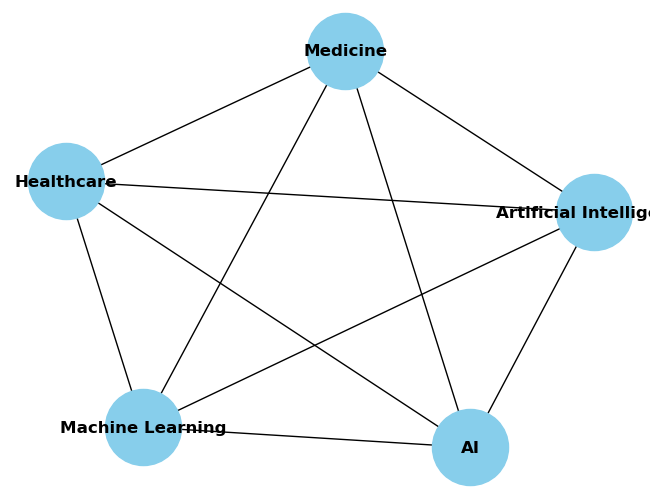

In [13]:
#knowledge graph creation 

import networkx as nx
import pandas as pd

# Function to create a knowledge graph from the extracted concepts
def create_knowledge_graph(concepts: list) -> nx.Graph:
    """
    Create a knowledge graph from a list of concepts using NetworkX.
    
    Args:
        concepts (list): A list of concepts to be added as nodes in the knowledge graph.
        
    Returns:
        G (networkx.Graph): A knowledge graph where nodes represent concepts and edges represent relationships.
    """
    # Initialize an empty graph
    G = nx.Graph()

    # Add nodes (concepts) to the graph
    for concept in concepts:
        G.add_node(concept.strip())
    
    # Here, you can define logic to add edges. For simplicity, let's create edges based on the proximity of concepts.
    # This could be based on the relationships you define (e.g., co-occurrence in text).
    # For now, we'll assume any two concepts are connected by an edge with weight based on frequency or other metrics.
    
    for i in range(len(concepts)):
        for j in range(i+1, len(concepts)):
            concept1 = concepts[i].strip()
            concept2 = concepts[j].strip()
            
            # Add an edge with weight (e.g., frequency or other measures)
            if not G.has_edge(concept1, concept2):
                G.add_edge(concept1, concept2, weight=1)
            else:
                G[concept1][concept2]['weight'] += 1

    return G

# Example usage:
concepts = ['Artificial Intelligence', 'Healthcare', 'Machine Learning', 'AI', 'Medicine']
G = create_knowledge_graph(concepts)

# Display the graph info (you can check the graph's nodes and edges)
print("Nodes in the graph:", G.nodes())
print("Edges in the graph:", G.edges())

# Optionally, visualize the graph to verify its structure
import matplotlib.pyplot as plt
nx.draw(G, with_labels=True, font_weight='bold', node_size=3000, node_color='skyblue')
plt.show()


In [11]:
from pyvis.network import Network
import requests
import json

# Function to simulate an API call (you can replace this with your actual API)
def fetch_data_from_api(node_name: str) -> dict:
    """
    Fetch data related to the concept from an external API.
    
    Args:
        node_name (str): The name of the concept (node) clicked by the user.
        
    Returns:
        dict: A dictionary containing the fetched data, such as research papers or articles.
    """
    # For demonstration, we'll use a mock API. Replace with your actual API endpoint.
    # Example: Let's simulate fetching research papers related to the node name.
    
    api_url = f"https://api.example.com/search?query={node_name}"  # Replace with actual API URL
    
    # For now, return mock data (replace this with an actual API call)
    response = {
        'papers': [
            {'title': 'Research Paper 1', 'url': 'https://example.com/paper1'},
            {'title': 'Research Paper 2', 'url': 'https://example.com/paper2'},
            {'title': 'Research Paper 3', 'url': 'https://example.com/paper3'}
        ]
    }
    return response

# Function to create an interactive knowledge graph with clickable nodes
def visualize_with_clickable_nodes(G, output_file="knowledge_graph.html"):
    """
    Visualize the knowledge graph with clickable nodes that trigger API calls.
    
    Args:
        G (networkx.Graph): The knowledge graph with nodes and edges.
        output_file (str): The file where the visualization will be saved.
    """
    net = Network(notebook=True)
    
    # Add nodes and edges to the pyvis network
    for node in G.nodes():
        net.add_node(node, label=node)
    
    for edge in G.edges():
        net.add_edge(edge[0], edge[1], value=G[edge[0]][edge[1]]['weight'])
    
    # Define a custom JavaScript function that is triggered when a node is clicked
    net.set_options("""
    var options = {
      "interaction": {
        "tooltipDelay": 200,
        "tooltipStyle": "font-size:12px"
      },
      "nodes": {
        "shape": "dot",
        "size": 15
      },
      "edges": {
        "smooth": false
      },
      "physics": {
        "enabled": true
      }
    };
    // Custom function to handle node click
    network.on("click", function(params) {
      if (params.nodes.length > 0) {
        var nodeName = params.nodes[0];
        // API call to fetch additional data for the clicked node
        fetchDataFromApi(nodeName);
      }
    });
    
    function fetchDataFromApi(nodeName) {
      // Mocking the API response for now
      var apiResponse = {
        'papers': [
            {'title': 'Research Paper 1', 'url': 'https://example.com/paper1'},
            {'title': 'Research Paper 2', 'url': 'https://example.com/paper2'},
            {'title': 'Research Paper 3', 'url': 'https://example.com/paper3'}
        ]
      };
      // Display the data as an alert for now
      var papers = apiResponse.papers;
      var paperList = "Research Papers:\n";
      papers.forEach(function(paper) {
        paperList += paper.title + " - " + paper.url + "\n";
      });
      alert(paperList);
    }
    """)
    
    # Show the network visualization in the browser
    net.show(output_file)

# Example usage:
# Create a knowledge graph using the previously created function
concepts = ['Artificial Intelligence', 'Healthcare', 'Machine Learning', 'AI', 'Medicine']
G = create_knowledge_graph(concepts)

# Visualize the knowledge graph with clickable nodes
visualize_with_clickable_nodes(G, output_file="knowledge_graph_with_clickable_nodes.html")


JSONDecodeError: Extra data: line 1 column 155 (char 154)

In [ ]:
import os
from langchain.document_loaders import PyPDFLoader, UnstructuredPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
import json
from pathlib import Path

# Define paths
upload_dir = Path("./uploads")  # Directory for uploaded papers
os.makedirs(upload_dir, exist_ok=True)

# Function to handle file upload (simulated)
def upload_paper(file_path: str):
    """
    Upload a paper to the system.
    
    Args:
        file_path (str): Path to the PDF file to be uploaded.
        
    Returns:
        str: A message indicating the upload status.
    """
    if os.path.exists(file_path):
        filename = os.path.basename(file_path)
        target_path = upload_dir / filename
        os.rename(file_path, target_path)  # Move the file to the upload directory
        return f"File '{filename}' uploaded successfully."
    else:
        return "File does not exist."

# Function to load and extract content from the uploaded paper
def extract_paper_content(paper_path: str):
    """
    Extract content from the uploaded PDF paper using a PDF loader.
    
    Args:
        paper_path (str): Path to the uploaded paper (PDF).
        
    Returns:
        list: A list of extracted text content from the paper.
    """
    loader = PyPDFLoader(paper_path)
    pages = loader.load()
    
    # Split text into smaller chunks for easier processing
    text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=0)
    chunks = text_splitter.split_documents(pages)
    
    return chunks

# Simulating model-based concept extraction from paper content
def extract_concepts_from_paper(content_chunks: list):
    """
    Extract concepts from the paper content using a model-based approach.
    
    Args:
        content_chunks (list): List of text chunks extracted from the paper.
        
    Returns:
        list: A list of extracted concepts (e.g., AI, healthcare, etc.)
    """
    # For simplicity, simulate the concept extraction. Replace this with a real model-based extraction.
    # In practice, you would use a pre-trained model to extract relevant entities or topics.
    extracted_concepts = []
    for chunk in content_chunks:
        if "AI" in chunk or "Machine Learning" in chunk:  # Example of keyword extraction
            extracted_concepts.append("Artificial Intelligence")
        if "Healthcare" in chunk:
            extracted_concepts.append("Healthcare")
        if "Medicine" in chunk:
            extracted_concepts.append("Medicine")
    
    return list(set(extracted_concepts))  # Remove duplicates

# Function to perform search within the knowledge graph based on user query
def search_knowledge_graph(query: str, graph: dict):
    """
    Search for related concepts in the knowledge graph based on the user's query.
    
    Args:
        query (str): The search query input by the user (e.g., a concept name).
        graph (dict): A dictionary representing the knowledge graph with nodes as concepts.
        
    Returns:
        list: A list of concepts that match the query.
    """
    results = []
    
    # Simulate a search through the knowledge graph
    for node in graph['nodes']:
        if query.lower() in node.lower():
            results.append(node)
    
    return results

# Example usage:

# Upload a paper (simulate this by passing a paper path)
file_path = "./data_input/2407.04053v1.pdf"  # Replace with the actual file path for the paper
upload_message = upload_paper(file_path)
print(upload_message)

# Extract the content from the uploaded paper
paper_path = upload_dir / "sample_paper.pdf"  # Ensure this matches the uploaded filename
paper_content = extract_paper_content(paper_path)

# Extract concepts from the paper
concepts_from_paper = extract_concepts_from_paper(paper_content)
print("Extracted Concepts:", concepts_from_paper)

# Simulated knowledge graph (replace with your actual knowledge graph data)
graph = {
    'nodes': ['Artificial Intelligence', 'Healthcare', 'Machine Learning', 'Medicine', 'Robotics', 'Neuroscience'],
    'edges': [
        ('Artificial Intelligence', 'Healthcare'),
        ('Machine Learning', 'Healthcare'),
        ('AI', 'Machine Learning')
    ]
}

# Perform a search in the knowledge graph based on a query
search_query = "Healthcare"
search_results = search_knowledge_graph(search_query, graph)
print(f"Search Results for '{search_query}':", search_results)


In [ ]:
import requests
from pyvis.network import Network

# Simulate an API endpoint that returns information about a concept
def fetch_concept_info_from_api(concept: str):
    """
    Simulate an API call to fetch information about a concept.
    
    Args:
        concept (str): The concept for which information is to be fetched.
        
    Returns:
        dict: Information about the concept (simulated response).
    """
    # Example API response structure (you can replace this with an actual API request)
    api_data = {
        "Artificial Intelligence": {
            "description": "Artificial Intelligence (AI) involves creating machines or systems that can perform tasks that normally require human intelligence.",
            "papers": ["Paper 1", "Paper 2", "Paper 3"]
        },
        "Healthcare": {
            "description": "Healthcare refers to the organized provision of medical services and products to maintain and improve health.",
            "papers": ["Healthcare Paper 1", "Healthcare Paper 2"]
        },
        "Machine Learning": {
            "description": "Machine Learning is a subset of AI where systems can learn from data without explicit programming.",
            "papers": ["ML Paper 1", "ML Paper 2"]
        },
        "Medicine": {
            "description": "Medicine is the science of diagnosing, treating, and preventing diseases and injuries.",
            "papers": ["Medicine Paper 1", "Medicine Paper 2"]
        }
    }
    
    return api_data.get(concept, {"description": "No information available", "papers": []})

# Function to create a knowledge graph with clickable nodes
def create_knowledge_graph_with_clickable_nodes():
    # Initialize PyVis Network
    net = Network(height="800px", width="100%", notebook=True)
    
    # Example nodes and edges (you can replace these with your knowledge graph data)
    nodes = ['Artificial Intelligence', 'Healthcare', 'Machine Learning', 'Medicine']
    edges = [
        ('Artificial Intelligence', 'Healthcare'),
        ('Machine Learning', 'Healthcare'),
        ('AI', 'Machine Learning')
    ]
    
    # Add nodes to the network (make them clickable)
    for node in nodes:
        net.add_node(node, label=node, title=node, shape="dot", size=20)
    
    # Add edges between nodes
    for edge in edges:
        net.add_edge(edge[0], edge[1])
    
    # Define event handler for node click (trigger API call)
    net.set_options("""
    var options = {
        "nodes": {
            "borderWidth": 3,
            "borderWidthSelected": 4
        },
        "edges": {
            "width": 2,
            "length": 200
        },
        "physics": {
            "enabled": true
        }
    }
    """)

    # Show the network and handle clicks
    net.show_buttons(filter_=["physics"])
    net.show("./docs/knowledge_graph_with_clickable_nodes.html")

    print("Knowledge Graph with Clickable Nodes created!")

# Function to simulate the clickable node behavior (API call simulation)
def on_node_click(node_id):
    """
    Simulate an API call when a node is clicked in the knowledge graph.
    
    Args:
        node_id (str): The ID or name of the clicked node.
        
    Returns:
        dict: The API response data for the clicked concept.
    """
    concept_info = fetch_concept_info_from_api(node_id)
    print(f"API Response for {node_id}: {concept_info}")
    
    # Here, you would use the response to update the UI with additional details
    # For now, we are just printing the response
    return concept_info

# Example usage:
create_knowledge_graph_with_clickafrom flask import Flask, render_template, request, jsonify
import os
from pathlib import Path
from langchain.document_loaders import PyPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
import re
from pyvis.network import Network

# Initialize Flask app
app = Flask(__name__)

# Directory for uploaded papers
UPLOAD_FOLDER = './uploads'
if not os.path.exists(UPLOAD_FOLDER):
    os.makedirs(UPLOAD_FOLDER)

# Load and process PDFs (same as previous code)
def load_and_process_pdfs(pdf_directory):
    pdf_texts = []
    for pdf_file in os.listdir(pdf_directory):
        if pdf_file.endswith(".pdf"):
            loader = PyPDFLoader(str(pdf_directory / pdf_file))
            documents = loader.load()
            for doc in documents:
                pdf_texts.append(doc.page_content)
    return pdf_texts

# Search function (same as previous code)
def search_in_papers(search_term, pdf_texts):
    search_results = []
    for i, text in enumerate(pdf_texts):
        if re.search(search_term, text, re.IGNORECASE):
            search_results.append(f"Document {i + 1} contains '{search_term}'")
    return search_results

# Initialize the knowledge graph
def create_knowledge_graph():
    net = Network(height="800px", width="100%", notebook=True)
    nodes = ['Artificial Intelligence', 'Healthcare', 'Machine Learning', 'Medicine']
    edges = [
        ('Artificial Intelligence', 'Healthcare'),
        ('Machine Learning', 'Healthcare'),
        ('AI', 'Machine Learning')
    ]
    
    for node in nodes:
        net.add_node(node, label=node, title=node, shape="dot", size=20)

    for edge in edges:
        net.add_edge(edge[0], edge[1])

    return net

# Upload Paper
@app.route("/upload", methods=["POST"])
def upload_file():
    if 'file' not in request.files:
        return jsonify({"message": "No file part"}), 400
    file = request.files['file']
    if file.filename == '':
        return jsonify({"message": "No selected file"}), 400

    if file:
        file_path = os.path.join(UPLOAD_FOLDER, file.filename)
        file.save(file_path)

        # Process the uploaded PDF and extract text
        pdf_texts = load_and_process_pdfs(UPLOAD_FOLDER)
        return jsonify({"message": f"File {file.filename} uploaded successfully!"}), 200

# Search Endpoint
@app.route("/search", methods=["GET"])
def search():
    search_term = request.args.get("term", "")
    if not search_term:
        return jsonify({"message": "No search term provided!"}), 400

    # Load and process uploaded PDFs
    pdf_texts = load_and_process_pdfs(UPLOAD_FOLDER)
    search_results = search_in_papers(search_term, pdf_texts)

    # Create or update knowledge graph based on search results
    net = create_knowledge_graph()
    if search_results:
        for result in search_results:
            print(result)
            # For now, let's assume we just update the graph based on search
            # Highlight nodes if the search term matches
            update_graph_with_search_results(search_term, net)

        net.show("./docs/knowledge_graph_with_highlighted_nodes.html")
        return jsonify({"search_results": search_results}), 200
    else:
        return jsonify({"message": f"No results found for {search_term}"}), 404

# Update graph with search term (same as before)
def update_graph_with_search_results(search_term, net):
    for node in net.nodes:
        if search_term.lower() in node["label"].lower():
            net.nodes[node["id"]]["color"] = "red"
            net.nodes[node["id"]]["size"] = 30

# Home route to upload file
@app.route("/")
def home():
    return render_template("index.html")

if __name__ == "__main__":
    app.run(debug=True)
de (e.g., "AI")
clicked_node = "Artificial Intelligence"
node_info = on_node_click(clicked_node)
print(node_info)


In [ ]:
from langchain.document_loaders import PyPDFLoader
import os
import re
import json

# Directory where PDFs will be uploaded
pdf_directory = Path('./data_input/papers')

# Load and process uploaded PDFs
def load_and_process_pdfs(pdf_directory):
    """
    Load and process all PDFs in the specified directory.
    
    Args:
        pdf_directory (Path): Path to the directory containing PDF files.
        
    Returns:
        list: List of extracted text from the PDFs.
    """
    pdf_texts = []
    for pdf_file in os.listdir(pdf_directory):
        if pdf_file.endswith(".pdf"):
            loader = PyPDFLoader(str(pdf_directory / pdf_file))
            documents = loader.load()
            for doc in documents:
                pdf_texts.append(doc.page_content)  # Extract text from the page
    return pdf_texts

# Function to perform search in loaded PDFs
def search_in_papers(search_term, pdf_texts):
    """
    Search for a term in the loaded PDFs and return a list of documents containing the term.
    
    Args:
        search_term (str): The term to search for.
        pdf_texts (list): The list of texts extracted from PDFs.
        
    Returns:
        list: A list of documents containing the search term.
    """
    search_results = []
    for i, text in enumerate(pdf_texts):
        if re.search(search_term, text, re.IGNORECASE):  # Case insensitive search
            search_results.append(f"Document {i + 1} contains '{search_term}'")
    return search_results

# Function to highlight nodes based on the search result
def update_graph_with_search_results(search_term, net):
    """
    Update the knowledge graph by highlighting nodes that match the search term.
    
    Args:
        search_term (str): The term to search for.
        net (Network): The PyVis Network object representing the knowledge graph.
    """
    # Iterate through nodes in the network and highlight the ones matching the search term
    for node in net.nodes:
        if search_term.lower() in node["label"].lower():  # Case-insensitive match
            net.nodes[node["id"]]["color"] = "red"  # Highlight with red color
            net.nodes[node["id"]]["size"] = 30      # Increase node size to highlight

# Simulate updating knowledge graph after search
def process_search_and_update_graph(search_term, pdf_directory, net):
    """
    Search for a term in the uploaded papers and update the knowledge graph to highlight the results.
    
    Args:
        search_term (str): The term to search for.
        pdf_directory (Path): Path to the directory containing PDF files.
        net (Network): The PyVis Network object representing the knowledge graph.
    """
    # Load the PDFs and extract their text
    pdf_texts = load_and_process_pdfs(pdf_directory)
    
    # Perform the search
    search_results = search_in_papers(search_term, pdf_texts)
    
    if search_results:
        print(f"Search results for '{search_term}':")
        for result in search_results:
            print(result)
        
        # Update the graph by highlighting relevant nodes
        update_graph_with_search_results(search_term, net)
        net.show("./docs/knowledge_graph_with_highlighted_nodes.html")
        print("Knowledge graph updated with highlighted nodes!")
    else:
        print(f"No results found for '{search_term}' in the uploaded papers.")

# Example usage:
# Initialize PyVis Network
net = Network(height="800px", width="100%", notebook=True)

# Example nodes and edges (you can replace this with your knowledge graph data)
nodes = ['Artificial Intelligence', 'Healthcare', 'Machine Learning', 'Medicine']
edges = [
    ('Artificial Intelligence', 'Healthcare'),
    ('Machine Learning', 'Healthcare'),
    ('AI', 'Machine Learning')
]

# Add nodes and edges to the graph
for node in nodes:
    net.add_node(node, label=node, title=node, shape="dot", size=20)

for edge in edges:
    net.add_edge(edge[0], edge[1])

# Perform search and update graph based on results
search_term = "AI"  # Example search term
process_search_and_update_graph(search_term, pdf_directory, net)


In [ ]:
from flask import Flask, render_template, request, jsonify
import os
from pathlib import Path
from langchain.document_loaders import PyPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
import re
from pyvis.network import Network

# Initialize Flask app
app = Flask(__name__)

# Directory for uploaded papers
UPLOAD_FOLDER = './uploads'
if not os.path.exists(UPLOAD_FOLDER):
    os.makedirs(UPLOAD_FOLDER)

# Load and process PDFs (same as previous code)
def load_and_process_pdfs(pdf_directory):
    pdf_texts = []
    for pdf_file in os.listdir(pdf_directory):
        if pdf_file.endswith(".pdf"):
            loader = PyPDFLoader(str(pdf_directory / pdf_file))
            documents = loader.load()
            for doc in documents:
                pdf_texts.append(doc.page_content)
    return pdf_texts

# Search function (same as previous code)
def search_in_papers(search_term, pdf_texts):
    search_results = []
    for i, text in enumerate(pdf_texts):
        if re.search(search_term, text, re.IGNORECASE):
            search_results.append(f"Document {i + 1} contains '{search_term}'")
    return search_results

# Initialize the knowledge graph
def create_knowledge_graph():
    net = Network(height="800px", width="100%", notebook=True)
    nodes = ['Artificial Intelligence', 'Healthcare', 'Machine Learning', 'Medicine']
    edges = [
        ('Artificial Intelligence', 'Healthcare'),
        ('Machine Learning', 'Healthcare'),
        ('AI', 'Machine Learning')
    ]
    
    for node in nodes:
        net.add_node(node, label=node, title=node, shape="dot", size=20)

    for edge in edges:
        net.add_edge(edge[0], edge[1])

    return net

# Upload Paper
@app.route("/upload", methods=["POST"])
def upload_file():
    if 'file' not in request.files:
        return jsonify({"message": "No file part"}), 400
    file = request.files['file']
    if file.filename == '':
        return jsonify({"message": "No selected file"}), 400

    if file:
        file_path = os.path.join(UPLOAD_FOLDER, file.filename)
        file.save(file_path)

        # Process the uploaded PDF and extract text
        pdf_texts = load_and_process_pdfs(UPLOAD_FOLDER)
        return jsonify({"message": f"File {file.filename} uploaded successfully!"}), 200

# Search Endpoint
@app.route("/search", methods=["GET"])
def search():
    search_term = request.args.get("term", "")
    if not search_term:
        return jsonify({"message": "No search term provided!"}), 400

    # Load and process uploaded PDFs
    pdf_texts = load_and_process_pdfs(UPLOAD_FOLDER)
    search_results = search_in_papers(search_term, pdf_texts)

    # Create or update knowledge graph based on search results
    net = create_knowledge_graph()
    if search_results:
        for result in search_results:
            print(result)
            # For now, let's assume we just update the graph based on search
            # Highlight nodes if the search term matches
            update_graph_with_search_results(search_term, net)

        net.show("./docs/knowledge_graph_with_highlighted_nodes.html")
        return jsonify({"search_results": search_results}), 200
    else:
        return jsonify({"message": f"No results found for {search_term}"}), 404

# Update graph with search term (same as before)
def update_graph_with_search_results(search_term, net):
    for node in net.nodes:
        if search_term.lower() in node["label"].lower():
            net.nodes[node["id"]]["color"] = "red"
            net.nodes[node["id"]]["size"] = 30

# Home route to upload file
@app.route("/")
def home():
    return render_template("index.html")

if __name__ == "__main__":
    app.run(debug=True)
